# Week 6 — Seoul Bike: External Data Integration & Context-Based Transfer (Team B)

**Goal:** Extend the Week 5 project by integrating a genuinely new contextual variable (`cloud_cover_pct`) from Open-Meteo, then estimate rental demand for a **held-out historical period** using similar **earlier** hours. The main Week 6 approach is transparent and non-AI (median of matched reference hours). Two separately calibrated Week 5 linear models are included as optional comparisons: the original model and **Week 5 + Cloud**, with one additional fitted cloud-cover coefficient. The Week 6 rule-based transfer remains the primary non-AI homework solution.

**Source of requirements:** `Week 6 Homework.pdf`, Part 1 (tasks 1–3) and Part 2, Team B (tasks 1–4).

**Not a live forecast:** We compare historical observations and historical estimates. A future-date Forecast API is a different, optional extension. Run the notebook top to bottom.

**Files:** `SeoulBikeData.csv` at the project root, and `open-meteo-37.57N126.96E27m.csv` in `Week-6/` or the root. The **Historical API is the primary source** (`WEATHER_SOURCE="api"`). Only if the API fails and `ALLOW_CSV_FALLBACK=True` is the supplied cloud CSV used as an explicitly logged backup. The fallback can be disabled to require a successful HTTP request.

## 1. Configuration and dependencies

The forecast target is **15–28 October 2018**, inclusive. All references and Week 5 training pairs are strictly earlier than the first test hour. Adjust these dates only if they exist in your input dataset. Matching thresholds are fixed before looking at test scores.

In [22]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

BIKE_FILE = 'SeoulBikeData.csv'
CLOUD_FILE = 'open-meteo-37.57N126.96E27m.csv'
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

TEST_START = pd.Timestamp('2018-10-15 00:00')
TEST_END = pd.Timestamp('2018-10-28 23:00')
MIN_MATCHES = 1
HOUR_TOLERANCE = 1
TEMPERATURE_TOLERANCE = 3.0
CLOUD_TOLERANCE = 20.0
WEATHER_SOURCE = 'api'          # 'api' (primary) or 'csv' (manual offline mode)
ALLOW_CSV_FALLBACK = True     # Set False to REQUIRE successful API access
API_URL = 'https://archive-api.open-meteo.com/v1/archive'
API_LAT, API_LON = 37.57469, 126.96

def find_file(filename):
    for path in [Path(filename), Path('..') / filename, Path('Week-6') / filename]:
        if path.exists():
            return path
    raise FileNotFoundError(f'Missing file: {filename}')

print('Test period:', TEST_START, 'to', TEST_END)


Test period: 2018-10-15 00:00:00 to 2018-10-28 23:00:00


## 2. Data catalogue (Homework Part 1.1 / Team B.1)

The Seoul CSV already includes hourly rentals, temperature, humidity, rainfall, wind, visibility, solar radiation, season, holiday and operating status. **Cloud cover is genuinely new**. Open-Meteo grid-cell data are not station-level bike measurements. We register both actual sources, including access modes, units, period, geography and limitations.

In [23]:
source_catalogue = pd.DataFrame([
    {
        'provider': 'UCI / Seoul Bike Sharing Demand',
        'source': 'https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand (SeoulBikeData.csv)', 'access': 'Local CSV',
        'variables_units': 'rentals count/hour; temperature °C; humidity %; season; holiday; operating status; other weather',
        'temporal_coverage': '2017-12-01 to 2018-11-30; hourly',
        'spatial_coverage': 'Seoul, South Korea; aggregate demand',
        'limitations': 'No station locations or inventory; historical observational data'
    },
    {
        'provider': 'Open-Meteo Historical Weather / ERA5',
        'source': API_URL + ' (or ' + CLOUD_FILE + ')', 'access': 'HTTP API / cached CSV fallback',
        'variables_units': 'cloud_cover_pct (%)',
        'temporal_coverage': 'Requested: Seoul Bike interval; hourly',
        'spatial_coverage': 'Grid point near 37.57469 N, 126.96 E',
        'limitations': 'Historical reanalysis, not an issued historical weather forecast; grid approximation; API may be unavailable'
    }
])
source_catalogue.to_csv(OUTPUT_DIR / 'source_catalogue.csv', index=False)
print(source_catalogue.to_string(index=False))


                            provider                                                                                source                         access                                                                                  variables_units                      temporal_coverage                     spatial_coverage                                                                                                  limitations
     UCI / Seoul Bike Sharing Demand https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand (SeoulBikeData.csv)                      Local CSV rentals count/hour; temperature °C; humidity %; season; holiday; operating status; other weather       2017-12-01 to 2018-11-30; hourly Seoul, South Korea; aggregate demand                                             No station locations or inventory; historical observational data
Open-Meteo Historical Weather / ERA5    https://archive-api.open-meteo.com/v1/archive (or open-meteo-37.57N126.96E27m.csv) HTTP 

## 3. Load and validate primary bike observations

Keep the original `SeoulBikeData.csv` untouched. Convert day-first dates plus hour into naive **Seoul-local** timestamps; retain only necessary columns but report invalid records and missing values first. A zero on a non-functioning day is not evidence of zero latent demand.

In [24]:
bike_path = find_file(BIKE_FILE)
bike_raw = pd.read_csv(bike_path, encoding='latin1')
bike_raw['Timestamp'] = (
    pd.to_datetime(bike_raw['Date'], dayfirst=True)
    + pd.to_timedelta(bike_raw['Hour'], unit='h')
)
required = ['Timestamp', 'Rented Bike Count', 'Temperature(°C)',
            'Humidity(%)', 'Seasons', 'Holiday', 'Functioning Day']
missing_bike = bike_raw[required].isna().sum().to_dict()
duplicate_bike = int(bike_raw['Timestamp'].duplicated().sum())
invalid_bike = int((bike_raw['Rented Bike Count'] < 0).sum())
invalid_humidity = int((~bike_raw['Humidity(%)'].between(0, 100)).sum())

bike = bike_raw[required].dropna().drop_duplicates('Timestamp').copy()
bike = bike[(bike['Rented Bike Count'] >= 0)
            & bike['Humidity(%)'].between(0, 100)
            & bike['Functioning Day'].isin(['Yes', 'No'])]
bike = bike.sort_values('Timestamp').reset_index(drop=True)
assert bike['Timestamp'].is_unique
print('Bike rows:', len(bike), '| duplicates:', duplicate_bike,
      '| negative rentals:', invalid_bike, '| invalid humidity:', invalid_humidity)
print('Raw missing counts:', missing_bike)


Bike rows: 8760 | duplicates: 0 | negative rentals: 0 | invalid humidity: 0
Raw missing counts: {'Timestamp': 0, 'Rented Bike Count': 0, 'Temperature(°C)': 0, 'Humidity(%)': 0, 'Seasons': 0, 'Holiday': 0, 'Functioning Day': 0}


## 4. Fetch cloud cover with Historical API or original CSV fallback

With `WEATHER_SOURCE="api"` (the default), actually send an HTTP GET request before any CSV reading. You may set `ALLOW_CSV_FALLBACK=False` to strictly require API success. When API access works, request `cloud_cover` **in Asia/Seoul** and save its raw JSON response as cache; on failure, use the **provided raw GMT CSV**. In the fallback, parse timestamps explicitly as UTC then convert to `Asia/Seoul`. Do not apply an extra +9 hours to the API response. This is a historical reanalysis; do not claim this is a forecast known in 2018.

In [25]:
def load_cloud_cover():
    """Prefer an HTTP Historical API request; explicitly disclose any CSV fallback."""
    if WEATHER_SOURCE not in ('api', 'csv'):
        raise ValueError("WEATHER_SOURCE must be 'api' or 'csv'")

    if WEATHER_SOURCE == 'api':
        params = {
            'latitude': API_LAT, 'longitude': API_LON,
            'start_date': bike['Timestamp'].min().strftime('%Y-%m-%d'),
            'end_date': bike['Timestamp'].max().strftime('%Y-%m-%d'),
            'hourly': 'cloud_cover', 'timezone': 'Asia/Seoul', 'models': 'era5'
        }
        print('Requesting primary weather source: Open-Meteo Historical API')
        print('API endpoint:', API_URL)
        try:
            response = requests.get(API_URL, params=params, timeout=35)
            response.raise_for_status()
            payload = response.json()
            hourly = payload['hourly']
            if len(hourly['time']) != len(hourly['cloud_cover']):
                raise ValueError('API time/cloud_cover lengths do not match')
            cloud = pd.DataFrame({
                'Timestamp': pd.to_datetime(hourly['time'], errors='raise'),
                'cloud_cover_pct': pd.to_numeric(hourly['cloud_cover'], errors='coerce')
            })
            # Timezone requested as Asia/Seoul: returned clock times already local.
            if cloud['Timestamp'].dt.tz is not None:
                cloud['Timestamp'] = cloud['Timestamp'].dt.tz_convert('Asia/Seoul').dt.tz_localize(None)
            (OUTPUT_DIR / 'open_meteo_api_raw.json').write_text(
                json.dumps(payload), encoding='utf-8'
            )
            print('HTTP Historical API request succeeded; using API data.')
            return cloud, 'Open-Meteo Historical API (Asia/Seoul local time)'
        except (requests.RequestException, KeyError, ValueError, TypeError) as exc:
            if not ALLOW_CSV_FALLBACK:
                raise RuntimeError('Historical API failed and CSV fallback is disabled') from exc
            print('WARNING: Historical API failed; CSV fallback is ACTIVE:', exc)
    else:
        print('Manual offline mode: using downloaded Open-Meteo CSV.')

    path = find_file(CLOUD_FILE)
    cloud_raw = pd.read_csv(path, skiprows=2)
    if 'time' not in cloud_raw or 'cloud_cover (%)' not in cloud_raw:
        raise ValueError('Unexpected cloud-cover CSV headers')
    cloud = pd.DataFrame({
        'Timestamp': pd.to_datetime(cloud_raw['time'], utc=True)
                      .dt.tz_convert('Asia/Seoul').dt.tz_localize(None),
        'cloud_cover_pct': pd.to_numeric(cloud_raw['cloud_cover (%)'], errors='coerce')
    })
    return cloud, 'Open-Meteo downloaded CSV (GMT converted to Asia/Seoul)'

cloud, cloud_provenance = load_cloud_cover()
cloud = cloud.sort_values('Timestamp').reset_index(drop=True)
cloud_duplicates = int(cloud['Timestamp'].duplicated().sum())
if cloud_duplicates:
    raise ValueError(f'Duplicate cloud timestamps: {cloud_duplicates}')
print('Cloud provenance:', cloud_provenance)
print('Cloud rows:', len(cloud), '| dates:', cloud.Timestamp.min(), '–', cloud.Timestamp.max())


Requesting primary weather source: Open-Meteo Historical API
API endpoint: https://archive-api.open-meteo.com/v1/archive
HTTP Historical API request succeeded; using API data.
Cloud provenance: Open-Meteo Historical API (Asia/Seoul local time)
Cloud rows: 8760 | dates: 2017-12-01 00:00:00 – 2018-11-30 23:00:00


## 5. Integrate, check quality and publish model-ready data

Use a **left join** so missing external weather cannot silently remove bike rows. Check a full hourly grid and valid 0–100 cloud cover. Persist integrated data separately from raw files. The test period is required to have full contextual coverage for a strict comparison; otherwise the notebook stops with a clear error.

In [26]:
integrated = bike.merge(cloud, on='Timestamp', how='left', validate='one_to_one')
assert len(integrated) == len(bike), 'Integration unexpectedly changed bike row count'
integrated['Cloud missing'] = integrated['cloud_cover_pct'].isna()

expected_hours = pd.date_range(integrated.Timestamp.min(), integrated.Timestamp.max(), freq='h')
missing_bike_hours = len(expected_hours.difference(pd.DatetimeIndex(integrated.Timestamp)))
invalid_cloud = int((integrated['cloud_cover_pct'].notna()
                     & ~integrated['cloud_cover_pct'].between(0, 100)).sum())
if invalid_cloud:
    raise ValueError(f'Invalid cloud-cover percentage values: {invalid_cloud}')

integrated['Hour'] = integrated['Timestamp'].dt.hour
integrated['Day type'] = np.where(integrated['Timestamp'].dt.day_of_week < 5,
                                  'Weekday', 'Weekend')
integrated['Is holiday'] = integrated['Holiday'].eq('Holiday')
integrated['Operating'] = integrated['Functioning Day'].eq('Yes')
integrated['Source cloud'] = cloud_provenance

quality_report = {
    'bike_rows': len(bike), 'integrated_rows': len(integrated),
    'bike_missing_hours': missing_bike_hours,
    'duplicate_bike_timestamps_removed': duplicate_bike,
    'missing_bike_fields_raw': missing_bike,
    'negative_rentals_raw': invalid_bike,
    'invalid_humidity_raw': invalid_humidity,
    'missing_cloud_on_bike_hours': int(integrated['Cloud missing'].sum()),
    'invalid_cloud_values': invalid_cloud,
    'cloud_provenance': cloud_provenance,
    'timezone_join': 'Asia/Seoul, naive local timestamps after normalization',
}
(OUTPUT_DIR / 'quality_report.json').write_text(
    json.dumps(quality_report, indent=2, ensure_ascii=False), encoding='utf-8'
)
integrated.to_csv(OUTPUT_DIR / 'integrated_seoul_bike.csv', index=False)
print(json.dumps(quality_report, indent=2, ensure_ascii=False))


{
  "bike_rows": 8760,
  "integrated_rows": 8760,
  "bike_missing_hours": 0,
  "duplicate_bike_timestamps_removed": 0,
  "missing_bike_fields_raw": {
    "Timestamp": 0,
    "Rented Bike Count": 0,
    "Temperature(°C)": 0,
    "Humidity(%)": 0,
    "Seasons": 0,
    "Holiday": 0,
    "Functioning Day": 0
  },
  "negative_rentals_raw": 0,
  "invalid_humidity_raw": 0,
  "missing_cloud_on_bike_hours": 0,
  "invalid_cloud_values": 0,
  "cloud_provenance": "Open-Meteo Historical API (Asia/Seoul local time)",
  "timezone_join": "Asia/Seoul, naive local timestamps after normalization"
}


## 6. Historical transfer protocol (Homework Part 1.3 / Team B.3)

Target: **2018-10-15 through 2018-10-28**. References: strictly earlier hours (`Timestamp < TEST_START`) from the same dataset. Fixed rules: same season, same weekday/weekend type, same holiday status, ±1 circular clock-hour, ±3°C. The extended variant also requires ±20 **percentage points** cloud cover. Only operating observations can serve as targets or references. If fewer than 3 matches: `insufficient_evidence` rather than an invented forecast. All thresholds are fixed, not tuned on the test observations.

In [27]:
reference = integrated[(integrated['Timestamp'] < TEST_START)
                       & integrated['Operating']].copy()
targets = integrated[integrated['Timestamp'].between(TEST_START, TEST_END)
                     & integrated['Operating']].copy()
assert not reference.empty and not targets.empty
assert reference.Timestamp.max() < targets.Timestamp.min()
assert targets['cloud_cover_pct'].notna().all(), 'Test period has missing external context'
print('Reference hours:', len(reference), '| Test hours:', len(targets))
print('Test period:', targets.Timestamp.min(), 'to', targets.Timestamp.max())


Reference hours: 7409 | Test hours: 336
Test period: 2018-10-15 00:00:00 to 2018-10-28 23:00:00


## 7. Transparent similarity rules and median transfer

The predictor never uses a test hour’s observed rental count. It sees only the target hour’s known calendar, temperature, and (optionally) cloud context. The number of matches is always preserved. `np.minimum(diff, 24-diff)` handles 23:00 vs 00:00 correctly.

In [28]:
def matching_hours(history, target, use_cloud=False):
    hour_diff = abs(history['Hour'] - int(target['Hour']))
    circular_hour_diff = np.minimum(hour_diff, 24 - hour_diff)
    mask = (
        (history['Timestamp'] < target['Timestamp'])
        & history['Operating']
        & (history['Seasons'] == target['Seasons'])
        & (history['Day type'] == target['Day type'])
        & (history['Is holiday'] == target['Is holiday'])
        & (circular_hour_diff <= HOUR_TOLERANCE)
        & ((history['Temperature(°C)'] - target['Temperature(°C)']).abs()
           <= TEMPERATURE_TOLERANCE)
    )
    if use_cloud:
        mask &= (history['cloud_cover_pct'].notna()
                 & pd.notna(target['cloud_cover_pct'])
                 & ((history['cloud_cover_pct'] - target['cloud_cover_pct']).abs()
                    <= CLOUD_TOLERANCE))
    return history.loc[mask]


def rule_based_estimates(history, future_hours, use_cloud=False):
    rows = []
    for _, target in future_hours.iterrows():
        matches = matching_hours(history, target, use_cloud)
        enough = len(matches) >= MIN_MATCHES
        rows.append({
            'Timestamp': target['Timestamp'],
            'Observed': float(target['Rented Bike Count']),
            'Estimated': float(matches['Rented Bike Count'].median()) if enough else np.nan,
            'Match count': len(matches),
            'Status': 'estimated' if enough else 'insufficient_evidence',
            'Method': 'Cloud matching' if use_cloud else 'Base matching',
            'Latest reference time': matches['Timestamp'].max() if len(matches) else pd.NaT
        })
    return pd.DataFrame(rows)

base_estimates = rule_based_estimates(reference, targets, use_cloud=False)
cloud_estimates = rule_based_estimates(reference, targets, use_cloud=True)
assert base_estimates.Timestamp.equals(cloud_estimates.Timestamp)
print('Base estimates:', base_estimates.Estimated.notna().sum(), '/', len(base_estimates))
print('Cloud estimates:', cloud_estimates.Estimated.notna().sum(), '/', len(cloud_estimates))


Base estimates: 312 / 336
Cloud estimates: 258 / 336


## 8. Week 5 calibrated linear model as a comparison (Homework Team B.4)

Fit **two** linear models with the same 23 hour-of-day dummy variables: (A) Week 5 original with `b0–b3`, and (B) **Week 5 + Cloud** with an additional `b4 × cloud_cover_pct` term. Refit **all** coefficients for both models. Use identical, cloud-complete training/test rows for a fair head-to-head comparison. Calibrate coefficients and hour effects using **only one-hour consecutive operating pairs that end before the test starts**. A target’s previous-hour observed rental count is available at the end of that prior hour (historical one-step replay); it is never the target itself. This is not free-running multi-step forecasting . The original Week 5 benchmark does not use cloud; the extra regression does. These are optional fitted benchmarks, not replacements for the required non-AI rule matcher.

In [29]:
now = integrated.iloc[:-1].reset_index(drop=True)
nxt = integrated.iloc[1:].reset_index(drop=True)
consecutive = nxt['Timestamp'].sub(now['Timestamp']).eq(pd.Timedelta(hours=1))
operating_pair = now['Operating'] & nxt['Operating']

pairs = pd.DataFrame({
    'Timestamp': nxt['Timestamp'],
    'D_current': now['Rented Bike Count'],
    'T_next': nxt['Temperature(°C)'],
    'H_next': nxt['Humidity(%)'],
    'Cloud_next': nxt['cloud_cover_pct'],
    'Hour_next': nxt['Timestamp'].dt.hour,
    'D_next': nxt['Rented Bike Count'],
})
pairs = pairs.loc[consecutive & operating_pair].reset_index(drop=True)
# Both regressions train/test on the same rows, avoiding unfair differences.
# Cloud missing in a row excludes it from BOTH regression variants.
complete = ['D_current', 'T_next', 'H_next', 'Cloud_next', 'D_next']
missing_regression_rows = int(pairs[complete].isna().any(axis=1).sum())
pairs = pairs.dropna(subset=complete).copy()
week5_train = pairs[pairs['Timestamp'] < TEST_START].copy()
week5_test = pairs[pairs['Timestamp'].between(TEST_START, TEST_END)].copy()
assert not week5_train.empty and not week5_test.empty
assert week5_train.Timestamp.max() < week5_test.Timestamp.min()

feature_names = ['b0', 'b1', 'b2', 'b3'] + [f'hour_{hour:02d}' for hour in range(1, 24)]
cloud_feature_names = ['b0', 'b1', 'b2', 'b3', 'b4_cloud'] + [f'hour_{hour:02d}' for hour in range(1, 24)]

def design_matrix(data, use_cloud=False):
    """Identical design; optional b4*cloud_cover inserted before hour effects."""
    columns = [
        np.ones(len(data)),
        data['D_current'].to_numpy(dtype=float),
        data['T_next'].to_numpy(dtype=float),
        data['H_next'].to_numpy(dtype=float),
    ]
    if use_cloud:
        columns.append(data['Cloud_next'].to_numpy(dtype=float))
    columns += [(data['Hour_next'].to_numpy() == h).astype(float)
                for h in range(1, 24)]
    return np.column_stack(columns)

X_train = design_matrix(week5_train, use_cloud=False)
X_train_cloud = design_matrix(week5_train, use_cloud=True)
y_train = week5_train['D_next'].to_numpy(dtype=float)
week5_coefficients, _, rank, _ = np.linalg.lstsq(X_train, y_train, rcond=None)
cloud_coefficients, _, cloud_rank, _ = np.linalg.lstsq(X_train_cloud, y_train, rcond=None)
if rank != len(feature_names) or cloud_rank != len(cloud_feature_names):
    raise ValueError('Regression training design matrix is not full rank')

week5_test['Week 5 calibrated'] = np.maximum(
    0.0, design_matrix(week5_test, use_cloud=False) @ week5_coefficients
)
week5_test['Week 5 + Cloud'] = np.maximum(
    0.0, design_matrix(week5_test, use_cloud=True) @ cloud_coefficients
)
assert week5_test[['Week 5 calibrated', 'Week 5 + Cloud']].notna().all().all()
assert len(week5_coefficients) == len(feature_names)
assert len(cloud_coefficients) == len(cloud_feature_names)
print('Shared regression train/test hours:', len(week5_train), '/', len(week5_test))
print('Regression candidate hours excluded for missing inputs:', missing_regression_rows)
print('Original Week 5 b0–b3:', np.round(week5_coefficients[:4], 3))
print('Week 5 + Cloud b0–b4:', np.round(cloud_coefficients[:5], 3))
print('Fitted cloud coefficient b4:', round(float(cloud_coefficients[4]), 5))


Shared regression train/test hours: 7399 / 336
Regression candidate hours excluded for missing inputs: 0
Original Week 5 b0–b3: [-23.464   0.871   4.164  -1.114]
Week 5 + Cloud b0–b4: [-22.399   0.869   4.221  -1.02   -0.133]
Fitted cloud coefficient b4: -0.13322


### Optional extension: Week 5 + Cloud equation

The original benchmark is `D_next = b0 + b1*D_current + b2*T_next + b3*H_next + hour_effect`.
The new benchmark is `D_next = b0 + b1*D_current + b2*T_next + b3*H_next + b4*Cloud_next + hour_effect`.
Both are **retrained from scratch on exactly the same reference rows**, and evaluated on exactly the same held-out target rows. In `design_matrix(data, use_cloud=True)`, the extra cloud column corresponds to `b4`. The fitted coefficient can be positive or negative and is not a causal effect. This is an **additional experiment**, not the mandatory non-AI rule-based transfer.

## 9. Compare on identical test timestamps, with honest coverage

Compute MAE and RMSE on each method’s available estimates; additionally compare all four methods on their **common predicted timestamps** to avoid favorable selection bias. The four methods do not necessarily cover every hour. Report match-count distribution and missing-estimate counts separately. The rule-based method does **not** use the Week 5 model output to construct its median.

In [30]:
results = base_estimates[['Timestamp', 'Observed']].copy()
results['Rule-based baseline'] = base_estimates['Estimated'].to_numpy()
results['Rule-based + cloud'] = cloud_estimates['Estimated'].to_numpy()
results['Base match count'] = base_estimates['Match count'].to_numpy()
results['Cloud match count'] = cloud_estimates['Match count'].to_numpy()
results = results.merge(
    week5_test[['Timestamp', 'Week 5 calibrated', 'Week 5 + Cloud']],
    on='Timestamp', how='left', validate='one_to_one'
)

methods = ['Rule-based baseline', 'Rule-based + cloud',
           'Week 5 calibrated', 'Week 5 + Cloud']
def score(y, p):
    errors = np.asarray(p, dtype=float) - np.asarray(y, dtype=float)
    return float(np.mean(np.abs(errors))), float(np.sqrt(np.mean(errors ** 2)))

metrics = []
for method in methods:
    available = results[method].notna()
    mae, rmse = score(results.loc[available, 'Observed'], results.loc[available, method]) if available.any() else (np.nan, np.nan)
    metrics.append({'Method': method, 'Evaluated hours': int(available.sum()),
                    'Total target hours': len(results), 'Coverage %': round(100*available.mean(), 2),
                    'MAE': mae, 'RMSE': rmse})
metrics = pd.DataFrame(metrics)

common = results[methods].notna().all(axis=1)
common_metrics = []
for method in methods:
    mae, rmse = score(results.loc[common, 'Observed'], results.loc[common, method]) if common.any() else (np.nan, np.nan)
    common_metrics.append({'Method': method, 'Common hours': int(common.sum()),
                           'MAE': mae, 'RMSE': rmse})
common_metrics = pd.DataFrame(common_metrics)

print('PER-MODEL COVERAGE / ERROR:')
print(metrics.round(2).to_string(index=False))
print('\nSAME TEST HOURS FOR ALL FOUR METHODS:')
print(common_metrics.round(2).to_string(index=False))
print('\nMissing baseline:', int(results['Rule-based baseline'].isna().sum()),
      '| Missing cloud:', int(results['Rule-based + cloud'].isna().sum()))
print('Mean base/cloud matches:', round(results['Base match count'].mean(), 1),
      '/', round(results['Cloud match count'].mean(), 1))


PER-MODEL COVERAGE / ERROR:
             Method  Evaluated hours  Total target hours  Coverage %    MAE   RMSE
Rule-based baseline              312                 336       92.86 186.21 304.37
 Rule-based + cloud              258                 336       76.79 253.69 391.06
  Week 5 calibrated              336                 336      100.00 147.46 217.50
     Week 5 + Cloud              336                 336      100.00 147.22 217.57

SAME TEST HOURS FOR ALL FOUR METHODS:
             Method  Common hours    MAE   RMSE
Rule-based baseline           258 179.59 286.58
 Rule-based + cloud           258 253.69 391.06
  Week 5 calibrated           258 135.09 199.06
     Week 5 + Cloud           258 134.55 198.64

Missing baseline: 24 | Missing cloud: 78
Mean base/cloud matches: 9.6 / 3.7


## 10. Required figure: Observed vs. context-based estimates

The first figure directly satisfies the Homework required plot. The separate second figure shows both calibrated regressions (Week 5 and Week 5 + Cloud) alongside observed demand, for a direct impact comparison. `asfreq("h")` inserts blank gaps without inventing observations; `NaN` segments are not connected. No historical predicted demand is presented as an observed measurement.

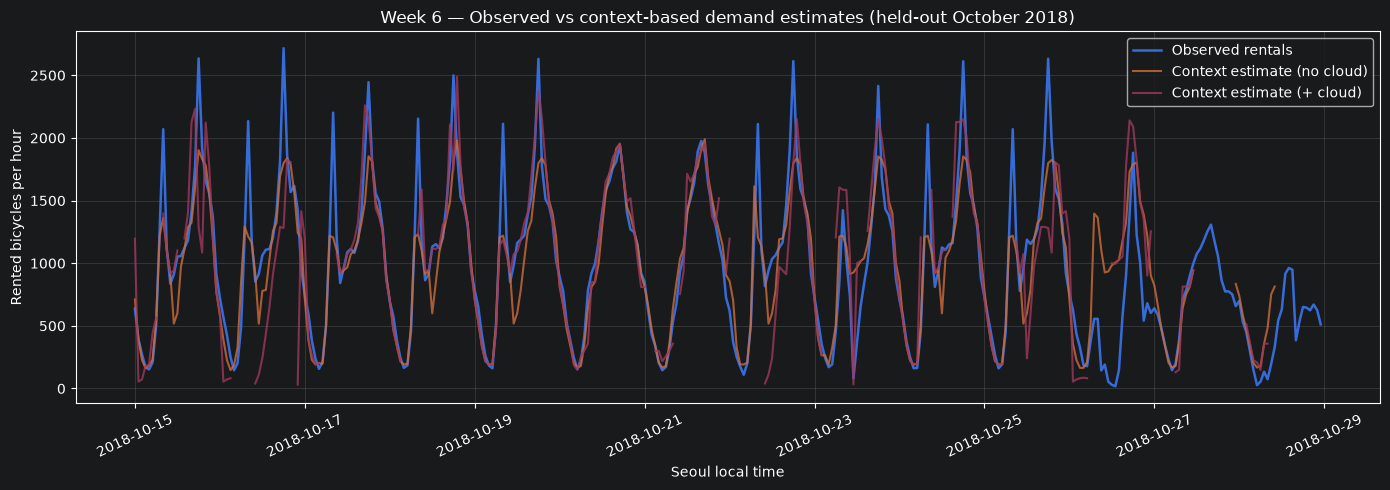

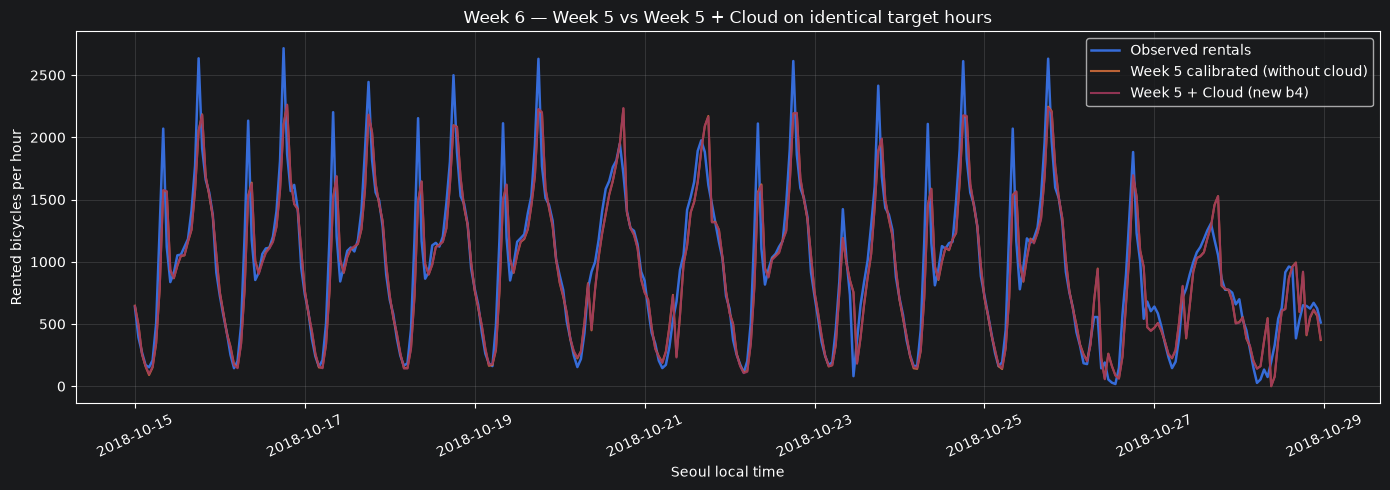

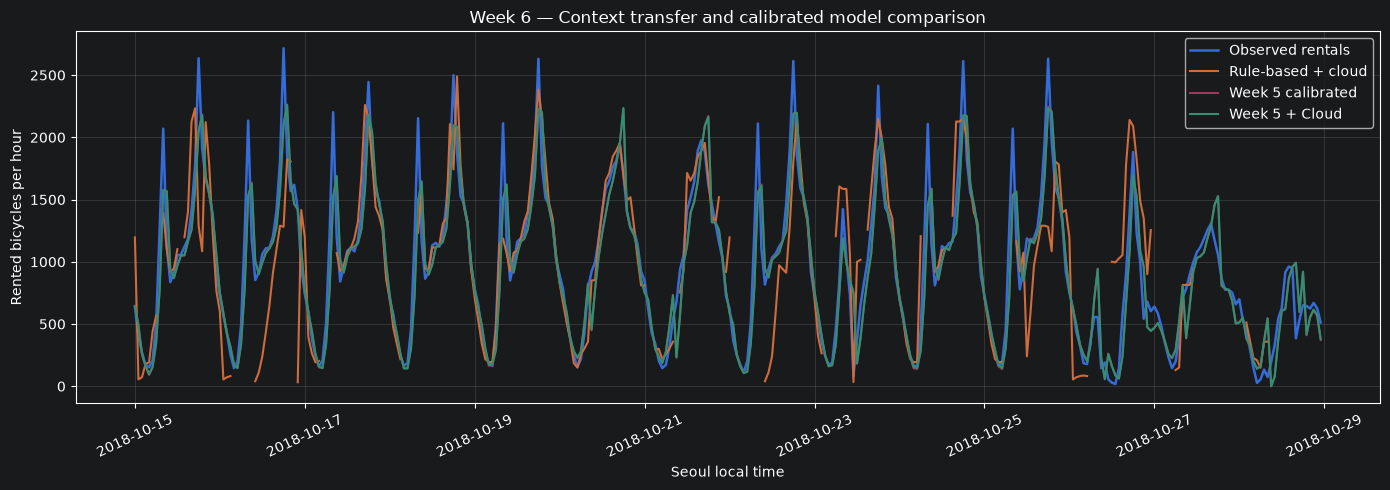

In [31]:
plot_table = results.set_index('Timestamp').asfreq('h')

plt.figure(figsize=(14, 5))
plt.plot(plot_table.index, plot_table['Observed'], label='Observed rentals', linewidth=1.8)
plt.plot(plot_table.index, plot_table['Rule-based baseline'], label='Context estimate (no cloud)', alpha=0.8)
plt.plot(plot_table.index, plot_table['Rule-based + cloud'], label='Context estimate (+ cloud)', alpha=0.8)
plt.title('Week 6 — Observed vs context-based demand estimates (held-out October 2018)')
plt.xlabel('Seoul local time')
plt.ylabel('Rented bicycles per hour')
plt.grid(alpha=0.25)
plt.legend()
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'required_observed_vs_context.png', dpi=150)
plt.show()

plt.figure(figsize=(14, 5))
plt.plot(plot_table.index, plot_table['Observed'], label='Observed rentals', linewidth=1.8)
plt.plot(plot_table.index, plot_table['Week 5 calibrated'], label='Week 5 calibrated (without cloud)', alpha=0.9)
plt.plot(plot_table.index, plot_table['Week 5 + Cloud'], label='Week 5 + Cloud (new b4)', alpha=0.9)
plt.title('Week 6 — Week 5 vs Week 5 + Cloud on identical target hours')
plt.xlabel('Seoul local time')
plt.ylabel('Rented bicycles per hour')
plt.grid(alpha=0.25)
plt.legend()
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'week5_vs_week5_cloud.png', dpi=150)
plt.show()

plt.figure(figsize=(14, 5))
plt.plot(plot_table.index, plot_table['Observed'], label='Observed rentals', linewidth=1.8)
plt.plot(plot_table.index, plot_table['Rule-based + cloud'], label='Rule-based + cloud')
plt.plot(plot_table.index, plot_table['Week 5 calibrated'], label='Week 5 calibrated')
plt.plot(plot_table.index, plot_table['Week 5 + Cloud'], label='Week 5 + Cloud')
plt.title('Week 6 — Context transfer and calibrated model comparison')
plt.xlabel('Seoul local time')
plt.ylabel('Rented bicycles per hour')
plt.grid(alpha=0.25)
plt.legend()
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'all_methods_comparison.png', dpi=150)
plt.show()


## 11. Output and audit checks

All generated datasets and charts stay in `outputs/`, **separate from the untouched raw CSV**. The checks below verify that no future reference time is selected and every estimate meets the declared minimum matching count. Missing values are flagged, not silently imputed. The final comparison is retrospective: historical weather is assumed available as contextual information at the target time; these are not real-time 2018 weather forecasts.

In [32]:
base_estimates.to_csv(OUTPUT_DIR / 'rule_estimates_baseline.csv', index=False)
cloud_estimates.to_csv(OUTPUT_DIR / 'rule_estimates_cloud.csv', index=False)
results.to_csv(OUTPUT_DIR / 'week6_comparison.csv', index=False)
week5_test[['Timestamp', 'D_next', 'Week 5 calibrated', 'Week 5 + Cloud']].to_csv(
    OUTPUT_DIR / 'week5_cloud_predictions.csv', index=False
)
pd.DataFrame({'feature': feature_names, 'coefficient': week5_coefficients}).to_csv(
    OUTPUT_DIR / 'week5_original_coefficients.csv', index=False
)
pd.DataFrame({'feature': cloud_feature_names, 'coefficient': cloud_coefficients}).to_csv(
    OUTPUT_DIR / 'week5_cloud_coefficients.csv', index=False
)
metrics.to_csv(OUTPUT_DIR / 'metrics_all_available.csv', index=False)
common_metrics.to_csv(OUTPUT_DIR / 'metrics_common_hours.csv', index=False)

assert len(integrated) == len(bike)
assert reference.Timestamp.max() < targets.Timestamp.min()
assert not ((base_estimates['Estimated'].notna()) & (base_estimates['Match count'] < MIN_MATCHES)).any()
assert not ((cloud_estimates['Estimated'].notna()) & (cloud_estimates['Match count'] < MIN_MATCHES)).any()
assert (base_estimates['Latest reference time'].dropna() < TEST_START).all()
assert (cloud_estimates['Latest reference time'].dropna() < TEST_START).all()
assert len(results) == len(targets)
assert 'cloud_cover_pct' in integrated.columns
assert 'Week 5 + Cloud' in results.columns
assert results['Week 5 + Cloud'].notna().sum() == results['Week 5 calibrated'].notna().sum()
assert len(metrics) == 4 and len(common_metrics) == 4
print('All validation assertions passed. Exports:', OUTPUT_DIR.resolve())


All validation assertions passed. Exports: C:\Users\Házi Donát Zsolt\Documents\personal\digital\University---Digital-Twins\Week-6\outputs


## 12. Interpretation, limitations and reproducibility

**What is observed?** `Observed` / `Rented Bike Count` are historical recorded rentals. **What is estimated?** Rule-based median demand and the Week 5 model outputs are calculated estimates; no station-level demand or inventory has been invented.

**New contextual feature:** `cloud_cover_pct` is imported from an external meteorological grid source and used in a transparent comparison with/without the cloud criterion. It **may reduce coverage** and need not improve MAE. An unfavorable result is still informative.

**No AI in the Week 6 transfer:** the main demand estimate is a fixed-rule historical median, not fitted regression or a new neural model. Both linear regressions are clearly labeled *optional benchmark extensions*: the original Week 5 calibrated model and the new Week 5 + Cloud re-calibration. They do not replace the required rule-based (non-AI) transfer.

**Time and uncertainty:** weather values are historical reanalysis, not historical operational forecasts. We use a consistent Asia/Seoul join; the weather grid cell represents an area, not each rental station. References are strictly prior to the test period. Holiday information reflects the available UCI coding; special events are not available.

**Evaluation:** compare both error and coverage. Use common-hours metrics when ranking models with different missing predictions.

**Future application (outside the Week 6 Homework):** a Forecast API could supply future weather context to this rule matcher, but without current demand observations and current-service context the estimates would represent historical-pattern scenarios, not validated live Digital Twin forecasts.